In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

In [4]:
class InvalidOrderError(Exception):
    pass

SOURCE_DATA_DIR = Path(r'D:\PROJECTS\QuickKart_DarkStore\dataset')
DESTINATION_DATA_DIR = Path(r'D:\PROJECTS\QuickKart_DarkStore\cleaned_dataset')
DESTINATION_DATA_DIR.mkdir(parents=True, exist_ok=True)

tables = {
    'orders' : {
        'required_columns': ['order_id','customer_id','store_id','order_ts','rider_id','delivered_ts','promised_mins','status','payment_mode'], 
        'text_columns': ['order_id','customer_id','store_id', 'rider_id', 'status','payment_mode'], 
        'date_columns': ['order_ts','delivered_ts'], 
        'numerical_columns': ['promised_mins']
    },

    'order_items':{
        'required_columns': ['order_id', 'sku_id', 'qty', 'mrp', 'discount_pct', 'fulfilled_flag'],
        'text_columns': ['order_id', 'sku_id'],
        'date_columns': [],
        'numerical_columns': ['qty', 'mrp', 'discount_pct', 'fulfilled_flag']
    },

    'stores':{
        'required_columns': ['store_id', 'city', 'zone', 'opening_date', 'parent_hub_id'],
        'text_columns': ['store_id', 'city', 'zone', 'parent_hub_id'],
        'date_columns': ['opening_date'],
        'numerical_columns': []
    },

    'riders':{
        'required_columns': ['rider_id', 'store_id', 'join_date', 'shift', 'vehicle_type'],
        'text_columns': ['rider_id', 'store_id', 'shift', 'vehicle_type'],
        'date_columns': ['join_date'],
        'numerical_columns': []
    },

    'products':{
        'required_columns': ['sku_id', 'sku_name', 'category', 'sub_category', 'brand', 'mrp', 'shelf_life_days'],
        'text_columns': ['sku_id', 'sku_name', 'category', 'sub_category', 'brand'],
        'date_columns': [],
        'numerical_columns': ['mrp', 'shelf_life_days']
    },

    'daily_stock_snapshot':{
        'required_columns': ['snapshot_date', 'store_id', 'sku_id', 'closing_qty', 'received_qty'],
        'text_columns': ['store_id', 'sku_id'],
        'date_columns': ['snapshot_date'],
        'numerical_columns': ['closing_qty', 'received_qty']
    }
}


In [5]:
import time
import logging
from functools import wraps

logging.basicConfig(
    filename="quickkart_pipeline.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)

def timer(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()

        try:
            return func(*args, **kwargs)
        finally:
            end = time.perf_counter()
            print(f"{func.__name__} executed in {end-start:.4f} seconds")

    return wrapper

def log(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        logging.info(f"Started: {func.__name__}")

        try:
            result = func(*args, **kwargs)
            logging.info(f"Completed: {func.__name__}")
            return result

        except Exception:
            logging.exception(f"Failed: {func.__name__}")
            raise

    return wrapper

In [6]:
@timer
@log
def load_dataset(file_name):
    
    try:
        file_path = SOURCE_DATA_DIR/file_name
        df = pd.read_csv(file_path) 
        print(f"\n{file_name} loaded succssfully.")

        try:

            required_columns = tables[Path(file_name).stem]['required_columns']

            missing_columns = [col for col in required_columns if col not in df.columns]

            if missing_columns:
                raise InvalidOrderError(f"Missing columns: {missing_columns}")

            text_columns = tables[Path(file_name).stem]['text_columns']

            for col in text_columns:
                df[col] = df[col].str.strip().str.upper()
                df[col] = df[col].replace(['','NA', 'N/A', 'na', 'n/a'], np.nan)

            date_columns = tables[Path(file_name).stem]['date_columns']

            for col in date_columns:
                df[col] = pd.to_datetime(df[col])


            numerical_columns = tables[Path(file_name).stem]['numerical_columns']

            for col in numerical_columns:
                df[col] = pd.to_numeric(df[col])


            print("Cleaning completed.")
            have_duplicates = df.duplicated().sum()

            if have_duplicates != 0:
                print("Duplicates records :-",have_duplicates)
                df.drop_duplicates(inplace=True)

            df.to_csv(DESTINATION_DATA_DIR/file_name, index=False)

            return df

        except InvalidOrderError as e:
            print("Data validation error:", e)

        except Exception as e:
            print("Cleaning pipeline error:", e)

        return None
        
    except FileNotFoundError:
        print(f"Eror :- {file_name} not found.")
    
    except Exception as e:
        print(f"Errror :- {e}")
    
    return None

In [7]:
daily_stock_snapshot = load_dataset('daily_stock_snapshot.csv')
orders = load_dataset('orders.csv')
order_items = load_dataset('order_items.csv')
stores = load_dataset('stores.csv')
products = load_dataset('products.csv')
riders = load_dataset('riders.csv')

# Remove completely duplicate rows in the orders dataset
d_order_id = orders[orders['delivered_ts'] < orders['order_ts']]['order_id'].to_list()
orders.drop(orders[orders['delivered_ts'] < orders['order_ts']].index, inplace = True)

# Deduplicate order IDs by prioritizing rows with fewer missing values in payment_mode and delivered_ts
orders['null_count'] = orders[['payment_mode', 'delivered_ts']].isnull().sum(axis=1)
orders = orders.sort_values(by=['order_id', 'null_count'])
orders = orders.drop_duplicates(subset=['order_id'], keep='first')
orders = orders.drop(columns=['null_count'])
orders = orders.reset_index(drop=True)

# Identify order IDs that only contain items with 0 quantity (no valid products purchased)
delete_order_id = order_items.groupby('order_id').agg({'qty':'sum'}).query('qty == 0').index.tolist()

# Drop item rows where quantity is 0
order_items.drop(order_items[order_items['qty'] == 0].index, inplace=True)
order_items.drop(order_items[order_items['sku_id'] > 'SKU02500'].index, inplace=True)

# Remove orders from the main orders table that have no valid item quantities
orders.drop(orders[orders['order_id'].isin(delete_order_id)].index, inplace=True)
order_items.drop(order_items[order_items['order_id'].isin(d_order_id)].index, inplace=True)

orders.to_csv(DESTINATION_DATA_DIR/'orders.csv', index=False)
order_items.to_csv(DESTINATION_DATA_DIR/'order_items.csv', index=False)

DATABASE = [daily_stock_snapshot, orders, order_items, stores, products, riders]


daily_stock_snapshot.csv loaded succssfully.
Cleaning completed.
load_dataset executed in 22.4892 seconds

orders.csv loaded succssfully.
Cleaning completed.
Duplicates records :- 589
load_dataset executed in 16.5419 seconds

order_items.csv loaded succssfully.
Cleaning completed.
Duplicates records :- 1744
load_dataset executed in 15.6042 seconds

stores.csv loaded succssfully.
Cleaning completed.
load_dataset executed in 0.1521 seconds

products.csv loaded succssfully.
Cleaning completed.
load_dataset executed in 0.1452 seconds

riders.csv loaded succssfully.
Cleaning completed.
load_dataset executed in 0.0722 seconds


In [8]:
@timer
@log
def calculate_delivery_status(df):

    df = df.copy()

    df = df[df["delivered_ts"].notna()].copy()

    df["is_on_time"] = (
        df["delivered_ts"] <=
        df["order_ts"] +
        pd.to_timedelta(df["promised_mins"], unit="m")
    )

    return df

In [9]:
delivery_df = orders[orders['delivered_ts'].notna()].copy()
delivery_df['is_on_time'] = np.where(delivery_df['delivered_ts'] <= delivery_df['order_ts'] + pd.to_timedelta(delivery_df['promised_mins'], unit='m'),1,0)

df = delivery_df.set_index('order_ts')

daily = df.resample('D').agg(total_delivered=('order_id', 'count'), on_time_orders=('is_on_time','sum'))
daily['daily_on_time_percentage'] = round(100 * daily['on_time_orders'] / daily['total_delivered'],2)

daily['rolling_7d_delivered'] = daily['total_delivered'].rolling(window=7, min_periods=7).sum()
daily['rolling_7d_on_time'] = daily['on_time_orders'].rolling(window=7, min_periods=7).sum()
daily['rolling_7d_on_time_percentage'] = round(100 * daily['rolling_7d_on_time'] / daily['rolling_7d_delivered'],2)

daily.reset_index(inplace=True)
daily['order_ts'] = pd.to_datetime(daily['order_ts'], format='%d-%m-%Y')

fig = px.line(
    daily,
    x='order_ts',
    y=['daily_on_time_percentage', 'rolling_7d_on_time_percentage']
)

fig.update_layout(
    width=1200,                                 
    height=600,                                 
    margin=dict(l=50, r=50, t=50, b=100),
    title=dict(
        text='Daily vs Rolling 7-Day On-Time Delivery Performance',
        font=dict(size=20)
    ),
    xaxis=dict(
        type='date',
        range=['2025-04-01', daily['order_ts'].max()],
        title='Date',
        showgrid=True,
        gridcolor='LightGrey'
    ),
    yaxis=dict(
        title='On-Time Delivery (%)',
        ticksuffix="%",
        showgrid=True,
        gridcolor='LightGrey'
    ),
    legend=dict(
        orientation="h",                        
        yanchor="top",
        y=-0.1,                                
        xanchor="center",
        x=0.5
    ),
    plot_bgcolor="white",                      
    hovermode="x unified"
)

fig.show()

In [10]:
delivery_df['delivery_time_minutes'] = (delivery_df['delivered_ts']-delivery_df['order_ts']).dt.total_seconds() / 60

percentile = [50, 75, 90, 95, 99]
percentiles = np.percentile(delivery_df['delivery_time_minutes'], percentile)

percentile_result = pd.DataFrame({
    'percentile' : [f"P{i}" for i in percentile],
    'delivery time (minutes)' : np.round(percentiles, 2)
})

fig = px.bar(
    percentile_result,
    x='percentile',
    y='delivery time (minutes)',
    text='delivery time (minutes)',
    title='Delivery Time Percentile Analysis'
)

fig.update_traces(
    textposition='outside'
)

fig.update_layout(
    width=1000,
    height=500,
    yaxis_title='Delivery Time (Minutes)',
    xaxis_title='Percentile',
    plot_bgcolor='white',
    hovermode=False
)

fig.show()


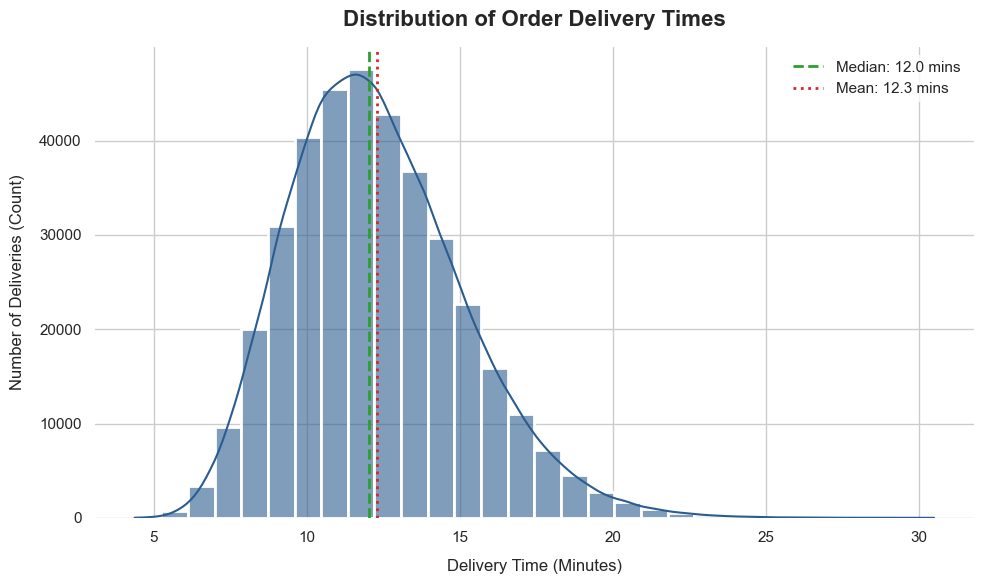

In [11]:
sns.set_theme(style="whitegrid", palette="muted")

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    data=delivery_df,
    x="delivery_time_minutes",
    bins=30,
    kde=True,
    element="bars",
    color="#2b5c8f",  
    alpha=0.6,  
    linewidth=2
)

# Calculate key metrics for data-driven annotations
median_time = delivery_df["delivery_time_minutes"].median()
mean_time = delivery_df["delivery_time_minutes"].mean()

# Add vertical reference lines for analytical context
plt.axvline(
    median_time,
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_time:.1f} mins",
)
plt.axvline(
    mean_time,
    color="#d62728",
    linestyle=":",
    linewidth=2,
    label=f"Mean: {mean_time:.1f} mins",
)

plt.title(
    "Distribution of Order Delivery Times",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Delivery Time (Minutes)", fontsize=12, labelpad=10)
plt.ylabel("Number of Deliveries (Count)", fontsize=12, labelpad=10)

sns.despine(left=True, bottom=True) 
plt.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=11)
plt.tight_layout()

plt.show()


In [12]:
class Rider:

    def __init__(self, rider_id, store_id, join_date, shift, vehicle_type):
        self._rider_id = rider_id
        self._store_id = store_id
        self._join_date = pd.to_datetime(join_date)
        self._shift = shift
        self._vehicle_type = vehicle_type

    @property
    def rider_id(self):
        return self._rider_id

    @property
    def store_id(self):
        return self._store_id

    @property
    def shift(self):
        return self._shift

    @property
    def vehicle_type(self):
        return self._vehicle_type

    @property
    def tenure_days(self):
        return (pd.Timestamp.today().normalize() - self._join_date).days

    def display_info(self):
        return {
            "Rider ID": self.rider_id,
            "Store ID": self.store_id,
            "Shift": self.shift,
            "Vehicle": self.vehicle_type,
            "Tenure (Days)": self.tenure_days
        }


class Store:

    def __init__(self, store_id, city, zone, opening_date, parent_hub_id):
        self._store_id = store_id
        self._city = city
        self._zone = zone
        self._opening_date = pd.to_datetime(opening_date)
        self._parent_hub_id = parent_hub_id

    @property
    def store_id(self):
        return self._store_id

    @property
    def city(self):
        return self._city

    @property
    def zone(self):
        return self._zone

    @property
    def parent_hub_id(self):
        return self._parent_hub_id

    @property
    def operating_days(self):
        return (pd.Timestamp.today().normalize() - self._opening_date).days

    def display_info(self):
        return {
            "Store ID": self.store_id,
            "City": self.city,
            "Zone": self.zone,
            "Parent Hub": self.parent_hub_id,
            "Operating Days": self.operating_days
        }

In [13]:
rider_objects = [Rider(**row) for row in riders.to_dict("records")]

store_objects = [Store(**row) for row in stores.to_dict("records")]

print("Total Rider Objects:", len(rider_objects))
print("Total Store Objects:", len(store_objects))

Total Rider Objects: 1200
Total Store Objects: 40


In [14]:
print(f"{'Rider ID':<10} | {'Store ID':<10} | {'Shift':<10} | {'Vehicle':<10} | {'Tenure (Days)':<10}")
for i in rider_objects:
    a = i.display_info()
    print(f"{a['Rider ID']:<10} | {a['Store ID']:<10} | {a['Shift']:<10} | {a['Vehicle']:<10} | {a['Tenure (Days)']:<10}")

Rider ID   | Store ID   | Shift      | Vehicle    | Tenure (Days)
R00001     | DS001      | MORNING    | EV SCOOTER | 333       
R00002     | DS002      | EVENING    | EV SCOOTER | 387       
R00003     | DS003      | MORNING    | EV SCOOTER | 483       
R00004     | DS004      | NIGHT      | EV SCOOTER | 416       
R00005     | DS005      | EVENING    | EV SCOOTER | 487       
R00006     | DS006      | MORNING    | BIKE       | 183       
R00007     | DS007      | EVENING    | EV SCOOTER | 315       
R00008     | DS008      | EVENING    | BIKE       | 651       
R00009     | DS009      | EVENING    | BIKE       | 495       
R00010     | DS010      | EVENING    | BIKE       | 443       
R00011     | DS011      | EVENING    | BICYCLE    | 657       
R00012     | DS012      | EVENING    | BIKE       | 567       
R00013     | DS013      | EVENING    | BIKE       | 544       
R00014     | DS014      | EVENING    | EV SCOOTER | 256       
R00015     | DS015      | EVENING    | EV SCOOTER | 

In [15]:
print(f"{'Store ID':<10} | {'City':<10} | {'Zone':<10} | {'Parent Hub':<10} | {'Operating Days':<10}")
for i in store_objects:
    a = i.display_info()
    print(f"{a['Store ID']:<10} | {a['City']:<10} | {a['Zone']:<10} | {a['Parent Hub']:<10} | {a['Operating Days']:<10}")

Store ID   | City       | Zone       | Parent Hub | Operating Days
DS001      | AHMEDABAD  | SOUTH      | nan        | 658       
DS002      | AHMEDABAD  | WEST       | DS001      | 1125      
DS003      | AHMEDABAD  | NORTH      | DS001      | 785       
DS004      | AHMEDABAD  | SOUTH      | DS001      | 939       
DS005      | AHMEDABAD  | WEST       | DS001      | 1177      
DS006      | AHMEDABAD  | SOUTH      | DS001      | 674       
DS007      | AHMEDABAD  | WEST       | DS001      | 717       
DS008      | AHMEDABAD  | NORTH      | DS001      | 1121      
DS009      | SURAT      | NORTH      | nan        | 634       
DS010      | SURAT      | WEST       | DS009      | 1233      
DS011      | SURAT      | CENTRAL    | DS009      | 768       
DS012      | SURAT      | SOUTH      | DS009      | 868       
DS013      | SURAT      | NORTH      | DS009      | 1036      
DS014      | SURAT      | EAST       | DS009      | 1388      
DS015      | VADODARA   | WEST       | nan        |

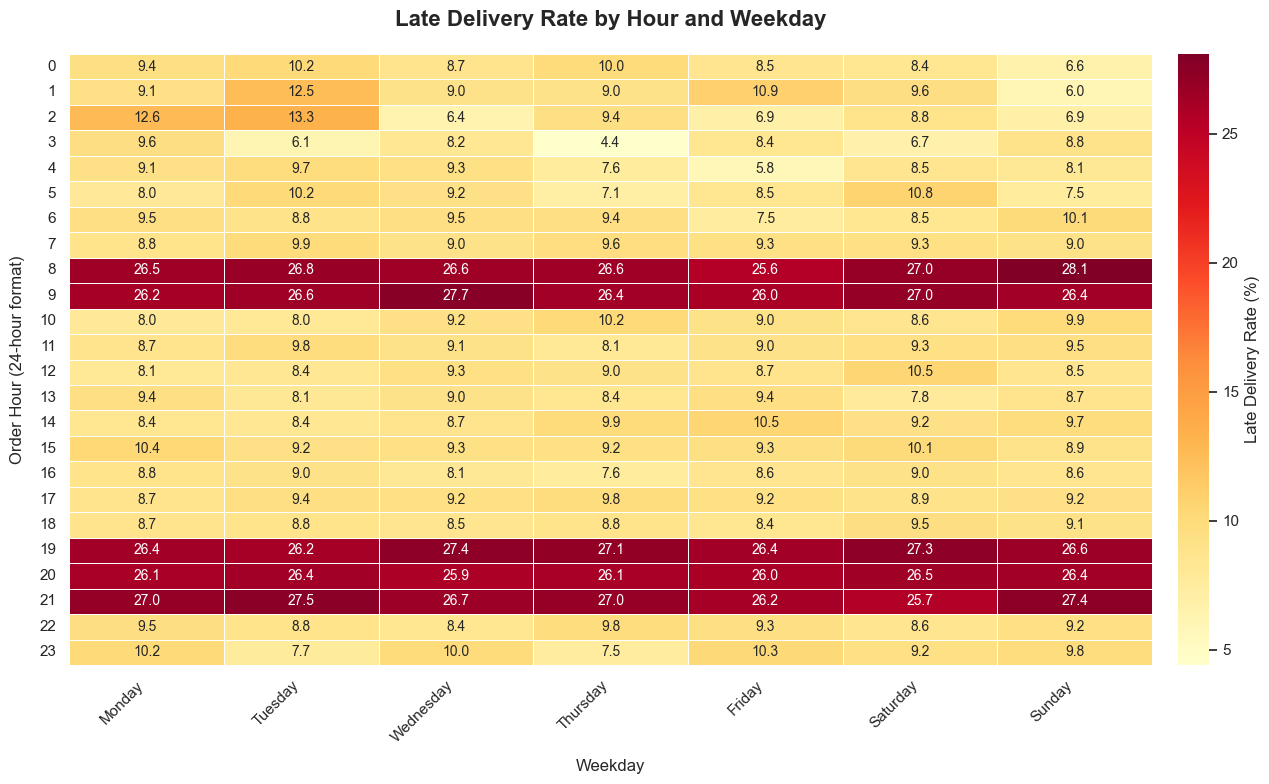

In [16]:
df = orders[orders['delivered_ts'].notna()].copy()

df['expected_delivery_ts'] = df['order_ts']+ pd.to_timedelta(df['promised_mins'], unit="m")

df['is_late'] = np.where(df['delivered_ts']>df['expected_delivery_ts'], 1, 0)

df['order_hour'] = df['order_ts'].dt.hour
df['weekday'] = df['order_ts'].dt.day_name()

weekday_order = [ 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heatmap_data = df.pivot_table(index='order_hour', columns='weekday', values='is_late', aggfunc='mean').mul(100)

heatmap_data = heatmap_data.reindex(columns=weekday_order)

heatmap_data.index.name = 'Order Hour'

heatmap_data.columns.name = 'Weekday'

sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 8))

ax = sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.1f', 
    cmap='YlOrRd', 
    linewidths=0.5, 
    linecolor='white',
    annot_kws={'size': 10},  
    cbar_kws={'label': 'Late Delivery Rate (%)', 'pad': 0.02}  
)

plt.title('Late Delivery Rate by Hour and Weekday', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Weekday', fontsize=12, labelpad=10)
plt.ylabel('Order Hour (24-hour format)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)                

plt.tight_layout()
plt.show()

08:00–09:00: Late-delivery rates are consistently around 25–28% across weekdays.

19:00–21:00: Another high-risk period, with rates around 26–28%.

Other hours: Most rates remain around 6–11%.

Weekday variation: The pattern is similar across all seven days. The problem appears more strongly associated with the hour than the weekday.

In [17]:
df = orders[orders['delivered_ts'].notna()].copy()

df['expected_delivery_ts'] = df['order_ts']+ pd.to_timedelta(df['promised_mins'], unit="m")

df['is_late'] = np.where(df['delivered_ts']>df['expected_delivery_ts'], 1, 0)

summary = df.groupby('store_id').agg(total_delivered=('order_id', 'count'), late_delivered=('is_late','sum')).reset_index()
summary['late_delivered_percentage'] = (100 * summary['late_delivered'] / summary['total_delivered']).round(2)
summary = summary.merge(stores[['store_id','city']], on='store_id', how='left')

top_stores = summary.nlargest(15, 'late_delivered').sort_values(by='late_delivered', ascending=False)

fig = px.bar(
    top_stores,
    x='late_delivered',
    y='store_id',
    orientation='h',
    color='late_delivered_percentage',
    color_continuous_scale='Reds',
    text='late_delivered',
    hover_data={
        'city': True,
        'total_delivered': True,
        'late_delivered': True,
        'late_delivered_percentage': ':.2f',
        'store_id': False
    },
    title='Top 15 Stores by Late Deliveries',
    labels={
        'store_id': 'Store ID',
        'late_delivered': 'Late Deliveries',
        'late_delivered_percentage': 'Late Delivery Rate (%)',
        'total_delivered': 'Total Delivered Orders',
        'city': 'City'
    }
)

fig.update_traces(
    textposition='outside',
    marker_line_width=0
)

fig.update_layout(
    width=1100,
    height=650,
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis_title='Number of Late Deliveries',
    yaxis_title='Store',
    coloraxis_colorbar_title='Late Rate (%)',
    hovermode='closest'
)

fig.update_yaxes(categoryorder='total ascending')

fig.show()